In [1]:

# ===== Cell 1 · Setup, load and check data =====
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA = Path.home() / "data"                       # /Users/lwuqiu/data
FIG  = Path.home() / "omega_charts"               # charts get saved here
FIG.mkdir(exist_ok=True)

# --- 1. What's in the folder
print("Files in", DATA)
for p in sorted(DATA.glob("*.csv")):
    print("   ", p.name)

EXPECTED = ["US_3M", "US_1Y", "US_2Y", "US_5Y", "US_7Y", "US_10Y", "US_20Y", "US_30Y",
            "UK_30Y", "DE_2Y", "DE_10Y", "DE_30Y", "FR_2Y", "FR_10Y", "FR_30Y",
            "IT_10Y", "JP_30Y", "BRENT"]
missing = [n for n in EXPECTED if not (DATA / f"{n}.csv").exists()]
print("\nMissing:", missing or "none")

# --- 2. Loader that works for both the script files (2026-10-14) and Investing.com (10/14/2026)
DATE_FORMATS = ["%Y-%m-%d", "%m/%d/%Y", "%d/%m/%Y", "%d.%m.%Y", "%b %d, %Y"]

def parse_dates(s):
    s = s.astype(str).str.strip()
    best = None
    for f in DATE_FORMATS:                         # keep the format that parses the most rows
        d = pd.to_datetime(s, format=f, errors="coerce")
        if best is None or d.notna().sum() > best.notna().sum():
            best = d
    return best

def load(name):
    df = pd.read_csv(DATA / f"{name}.csv", encoding="utf-8-sig")
    df.columns = [c.strip().strip('"') for c in df.columns]
    price = pd.to_numeric(df["Price"].astype(str).str.replace(",", ""), errors="coerce")
    s = pd.Series(price.values, index=parse_dates(df["Date"]), name=name)
    s = s[s.index.notna()].dropna().sort_index()
    return s[~s.index.duplicated()]

px = pd.concat({n: load(n) for n in EXPECTED if n not in missing}, axis=1).loc["2016-01-01":]
YIELDS = [c for c in px.columns if c != "BRENT"]

# --- 3. Sanity check: dates, coverage, last value, biggest daily move
def biggest_move(c):
    d = px[c].dropna().diff()
    d = d * 100 if c in YIELDS else d / px[c].dropna().shift() * 100   # bp for yields, % for Brent
    return pd.Series({"max |1d move|": round(d.abs().max(), 1),
                      "on": d.abs().idxmax().date()})

summary = pd.concat([
    pd.DataFrame({
        "first": px.apply(lambda c: c.first_valid_index().date()),
        "last":  px.apply(lambda c: c.last_valid_index().date()),
        "obs":   px.count(),
        "last value": px.apply(lambda c: c.dropna().iloc[-1]).round(3),
        "min":   px.min().round(2),
        "max":   px.max().round(2),
    }),
    px.columns.to_series().apply(biggest_move),
], axis=1)
print("\nUnits: yields in %, Brent in USD/bbl; 1d move in bp (yields) or % (Brent)")
display(summary)

# --- 4. House style for all charts (swap these hex codes for Omega's brand colours)
COL = {"US": "#1F4E79", "UK": "#C0392B", "DE": "#2C3E50", "FR": "#7D3C98",
       "IT": "#1E8449", "JP": "#D4A017", "BRENT": "#6E4B1F",
       "ink": "#0B1320", "muted": "#6B7280", "grid": "#E3E7EE"}

plt.rcParams.update({
    "figure.figsize": (10, 5.2), "figure.dpi": 110, "savefig.dpi": 300,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": COL["muted"], "axes.labelcolor": COL["ink"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COL["grid"], "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "legend.frameon": False, "xtick.color": COL["muted"], "ytick.color": COL["muted"],
})

def finish(fig, name, source):
    """Source line bottom-left, Omega tag bottom-right, save as PNG."""
    fig.text(0.01, 0.005, f"Source: {source}; Omega Capital calculations.",
             fontsize=8, color=COL["muted"], ha="left")
    fig.text(0.99, 0.005, "Ω OMEGA CAPITAL · Rates Research", fontsize=8,
             color=COL["muted"], ha="right", weight="bold")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    print("saved:", FIG / f"{name}.png")

print(f"\nLoaded {px.shape[1]} series, {px.index.min().date()} -> {px.index.max().date()}")


Files in /Users/lwuqiu/data

Missing: ['US_3M', 'US_1Y', 'US_2Y', 'US_5Y', 'US_7Y', 'US_10Y', 'US_20Y', 'US_30Y', 'UK_30Y', 'DE_2Y', 'DE_10Y', 'DE_30Y', 'FR_2Y', 'FR_10Y', 'FR_30Y', 'IT_10Y', 'JP_30Y', 'BRENT']


ValueError: No objects to concatenate

In [6]:
# ===== Cell 0 · Map Investing.com file names to standard names =====
import shutil
from pathlib import Path

DATA = Path.home() / "data"
RENAME = {
    "Brent Oil Futures Historical Data":                   "BRENT",
    "France 2-Year Bond Yield Historical Data":            "FR_2Y",
    "France 10-Year Bond Yield Historical Data":           "FR_10Y",
    "France 30-Year Bond Yield Historical Data":           "FR_30Y",
    "Italy 10-Year Bond Yield Historical Data":            "IT_10Y",
    "United Kingdom 30-Year Bond Yield Historical Data":   "UK_30Y",
}
for prefix, std in RENAME.items():
    hits = sorted(DATA.glob(f"{prefix}*.csv"), key=lambda p: p.stat().st_mtime)
    if hits:
        shutil.copy(hits[-1], DATA / f"{std}.csv")        # newest download wins
        print(f"{hits[-1].name:55s} -> {std}.csv")
    else:
        print(f"NOT FOUND: {prefix}  (download it, then re-run this cell)")

Brent Oil Futures Historical Data.csv                   -> BRENT.csv
France 2-Year Bond Yield Historical Data.csv            -> FR_2Y.csv
France 10-Year Bond Yield Historical Data.csv           -> FR_10Y.csv
France 30-Year Bond Yield Historical Data.csv           -> FR_30Y.csv
Italy 10-Year Bond Yield Historical Data.csv            -> IT_10Y.csv
United Kingdom 30-Year Bond Yield Historical Data.csv   -> UK_30Y.csv


saved: /Users/lwuqiu/omega_charts/chart1_global_30y.png


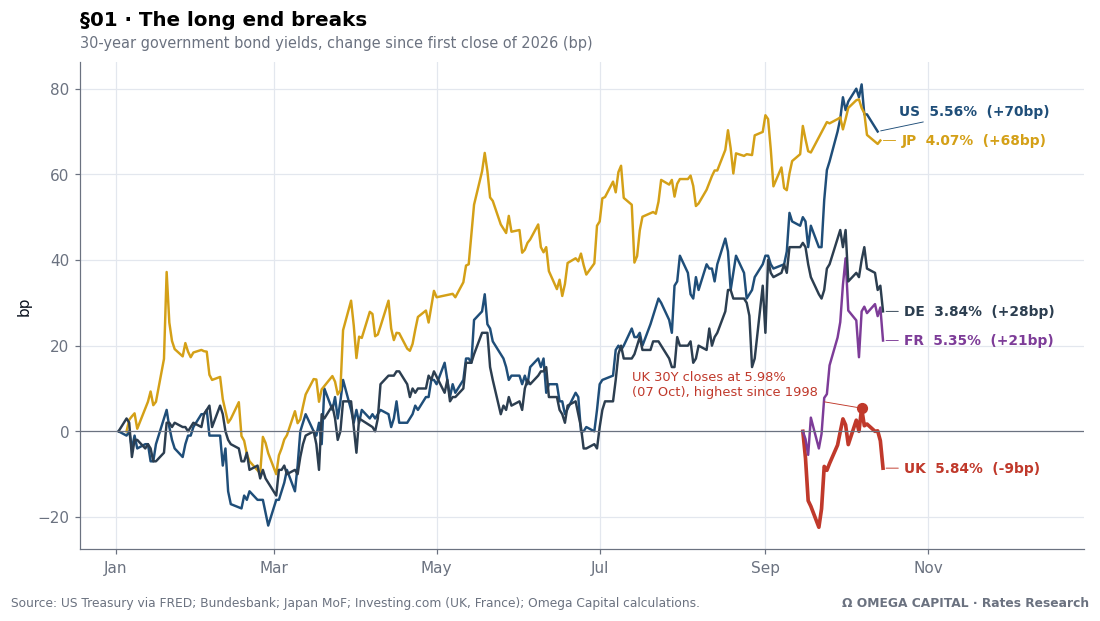

,1st 2026 close (%),Latest (%),Change (bp),2026 high (%),High on,30Y par bond price chg (%)
Market,,,,,,
US,4.86,5.56,70,5.67,2026-10-07,-10.2
JP,3.39,4.07,68,4.17,2026-10-06,-11.7
DE,3.56,3.84,28,4.03,2026-09-29,-5.0
FR,5.14,5.35,21,5.55,2026-10-01,-3.1
UK,5.92,5.84,-9,5.98,2026-10-07,1.2


In [9]:
# ===== Cell 2 · Chart 1: The long end breaks (global 30Y yields) =====
BASE = "2026-01-01"
LONG = {"UK": "UK_30Y", "US": "US_30Y", "FR": "FR_30Y", "JP": "JP_30Y", "DE": "DE_30Y"}

def bond_price(coupon, y, n=30, f=2):
    """Price per 100 of an n-year bond paying `coupon` (decimal) f times a year, at yield y (decimal)."""
    t = np.arange(1, n * f + 1)
    return np.sum(coupon / f * 100 / (1 + y / f) ** t) + 100 / (1 + y / f) ** (n * f)

fig, ax = plt.subplots(figsize=(10, 5.6))
rows, ends = [], []
for cc, col in LONG.items():
    s = px[col].loc[BASE:].dropna()                 # no forward-fill: each market's own trading days
    chg = (s - s.iloc[0]) * 100                     # bp change vs first 2026 close
    ax.plot(chg.index, chg, color=COL[cc], lw=2.4 if cc == "UK" else 1.6, label=cc)
    ends.append([cc, chg.index[-1], chg.iloc[-1], s.iloc[-1]])

    # 30Y par bond bought at the first 2026 close, repriced at today's yield (price return only)
    p_now = bond_price(s.iloc[0] / 100, s.iloc[-1] / 100)
    rows.append({"Market": cc,
                 "1st 2026 close (%)": round(s.iloc[0], 2),
                 "Latest (%)": round(s.iloc[-1], 2),
                 "Change (bp)": round(chg.iloc[-1]),
                 "2026 high (%)": round(s.max(), 2),
                 "High on": s.idxmax().date(),
                 "30Y par bond price chg (%)": round(p_now - 100, 1)})

# --- end-of-line labels, pushed apart so they never overlap
ax.axhline(0, color=COL["muted"], lw=0.8)
lo, hi = ax.get_ylim()
gap = 0.06 * (hi - lo)
ends.sort(key=lambda e: e[2])
pos = [e[2] for e in ends]
for i in range(1, len(pos)):
    pos[i] = max(pos[i], pos[i - 1] + gap)
for (cc, x, yv, lvl), yl in zip(ends, pos):
    ax.annotate(f"{cc}  {lvl:.2f}%  ({yv:+.0f}bp)", xy=(x, yv), xytext=(x + pd.Timedelta(days=8), yl),
                color=COL[cc], fontsize=9, weight="bold", va="center",
                arrowprops=dict(arrowstyle="-", color=COL[cc], lw=0.6))
ax.set_xlim(right=px.index.max() + pd.Timedelta(days=75))

# --- mark the UK 6% break
uk = px["UK_30Y"].loc[BASE:].dropna()
d_hi = uk.idxmax()
y_hi = (uk.max() - uk.iloc[0]) * 100
ax.scatter([d_hi], [y_hi], s=40, color=COL["UK"], zorder=5)
ax.annotate(f"UK 30Y closes at {uk.max():.2f}%\n({d_hi:%d %b}), highest since 1998",
            xy=(d_hi, y_hi), xytext=(-150, 8), textcoords="offset points",
            fontsize=8.5, color=COL["UK"], arrowprops=dict(arrowstyle="-", color=COL["UK"], lw=0.6))

ax.set_title("§01 · The long end breaks", pad=24)
ax.text(0, 1.03, "30-year government bond yields, change since first close of 2026 (bp)",
        transform=ax.transAxes, fontsize=9.5, color=COL["muted"])
ax.set_ylabel("bp")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
finish(fig, "chart1_global_30y",
       "US Treasury via FRED; Bundesbank; Japan MoF; Investing.com (UK, France)")
plt.show()

table1 = pd.DataFrame(rows).set_index("Market").sort_values("Change (bp)", ascending=False)
display(table1)